# Neural network for Chronic Kidney Disease prediction

A small Keras network (two hidden layers of 15 units with dropout) on the UCI CKD dataset: 400 patients, 24 clinical
attributes, label 1 = CKD.

## Evaluation protocol

The data is split before anything is fitted, into three separate sets:

| Set | Rows | Used for |
|:--|:--|:--|
| training | 256 | fitting imputation, encoding, oversampling, scaling, PCA and the network weights |
| validation | 64 | early stopping and choosing the decision threshold |
| test | 80 | the final score, at threshold 0.5 and at the threshold chosen on validation |

Oversampling only touches the training rows, so no copy of a training row can reach the validation or test set. The
whole pipeline is then repeated in repeated stratified 5-fold cross-validation for a less noisy estimate.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import logging
# Hide TensorFlow's GPU-on-Windows and retracing notices. TensorFlow installs its own INFO-level handler
# on import unless the root logger already has one, so give the root logger a no-op handler first.
logging.getLogger().addHandler(logging.NullHandler())
logging.getLogger("tensorflow").setLevel(logging.ERROR)
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, f1_score, precision_recall_curve, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from imblearn.over_sampling import RandomOverSampler

SEED = 7
keras.utils.set_random_seed(SEED)
sns.set_theme()
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.15.1 | backend: tensorflow


## Load and clean the data

In [2]:
def load_ckd(path="kidney_disease.csv"):
    """Load the UCI CKD data and repair its formatting problems."""
    df = pd.read_csv(path)
    # Some text cells carry stray tabs or spaces: 'ckd\t', '\tno', ' yes'.
    for col in df.columns:
        if pd.api.types.is_string_dtype(df[col]):
            df[col] = df[col].str.strip()
    # pcv, wc and rc are numeric but are stored as text because of '\t?' placeholders.
    for col in ["pcv", "wc", "rc"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")  # '?' becomes NaN
    return df


NUMERIC = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]
CATEGORICAL = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]

df = load_ckd()
X = df[NUMERIC + CATEGORICAL]
y = (df["classification"] == "ckd").astype(int).to_numpy()   # 1 = CKD
print(X.shape, "| CKD:", y.sum(), "| not CKD:", (1 - y).sum())

(400, 24) | CKD: 250 | not CKD: 150


## Split: train / validation / test

In [3]:
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.2, stratify=y_rest, random_state=SEED)
for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:10s} {len(part):3d} rows  CKD={part.sum():3d}  not CKD={(1 - part).sum():3d}")

train      256 rows  CKD=160  not CKD= 96


validation  64 rows  CKD= 40  not CKD= 24
test        80 rows  CKD= 50  not CKD= 30


## Preprocessing, fitted on the training rows only

Impute (median / most frequent), one-hot encode, oversample the minority class, scale to [-1, 1], then PCA keeping
95% of the variance. Validation and test rows are only transformed.

In [4]:
def fit_preprocessing(X_fit, y_fit, seed=SEED):
    """Fit the preprocessing on X_fit only. Returns oversampled training arrays and a transform for other rows."""
    columns = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUMERIC),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))]), CATEGORICAL),
    ])
    A = columns.fit_transform(X_fit)
    A, y_bal = RandomOverSampler(random_state=seed).fit_resample(A, y_fit)
    scaler = MinMaxScaler(feature_range=(-1, 1)).fit(A)
    pca = PCA(n_components=0.95).fit(scaler.transform(A))

    def transform(X_other):
        return pca.transform(scaler.transform(columns.transform(X_other)))

    return pca.transform(scaler.transform(A)), y_bal, transform


A_train, yb_train, transform = fit_preprocessing(X_train, y_train)
A_val, A_test = transform(X_val), transform(X_test)
print("training rows after oversampling:", A_train.shape, "| CKD / not CKD =", yb_train.sum(), "/", (1 - yb_train).sum())
print("PCA components kept:", A_train.shape[1])

training rows after oversampling: (320, 15) | CKD / not CKD = 160 / 160
PCA components kept: 15


## Model

In [5]:
def build_model(n_inputs):
    model = keras.Sequential([
        keras.Input(shape=(n_inputs,)),
        keras.layers.Dense(15, activation="relu"),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(15, activation="relu"),
        keras.layers.Dropout(0.4),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


model = build_model(A_train.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 15)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 496 (1.94 KB)

 Trainable params: 496 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

## Training with early stopping

Up to 500 epochs; training stops when the validation loss has not improved for 20 epochs, and the best weights are
restored.

In [6]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
history = model.fit(A_train, yb_train, validation_data=(A_val, y_val), epochs=500, batch_size=32,
                    callbacks=[early_stop], verbose=0)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"stopped after {len(history.history['loss'])} epochs; best validation loss at epoch {best_epoch}")
print("at the best epoch: train accuracy %.4f, validation accuracy %.4f" % (
    history.history["accuracy"][best_epoch - 1], history.history["val_accuracy"][best_epoch - 1]))

stopped after 156 epochs; best validation loss at epoch 136
at the best epoch: train accuracy 1.0000, validation accuracy 1.0000


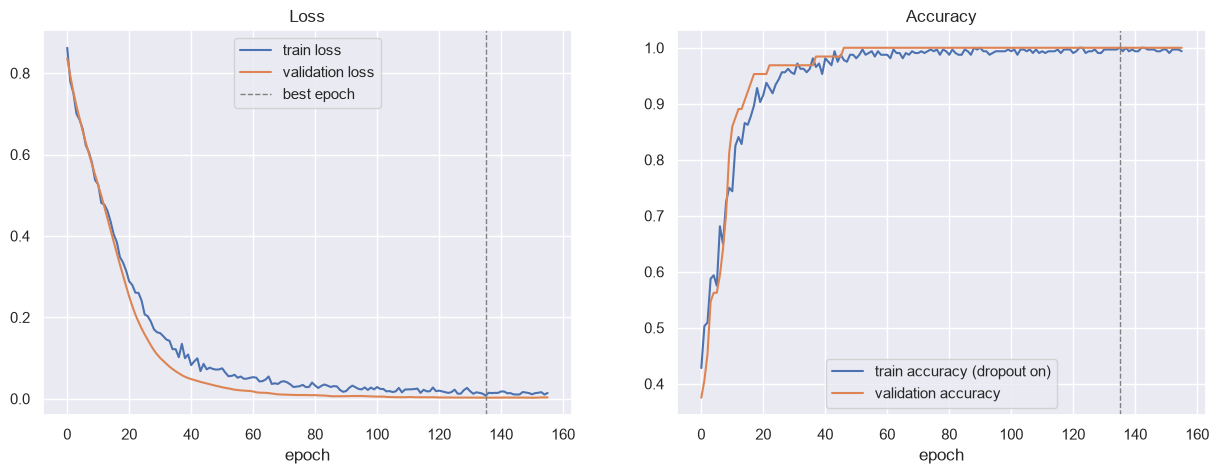

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
ax1.plot(history.history["loss"], label="train loss")
ax1.plot(history.history["val_loss"], label="validation loss")
ax1.axvline(best_epoch - 1, color="grey", ls="--", lw=1, label="best epoch")
ax1.set(title="Loss", xlabel="epoch")
ax1.legend()
ax2.plot(history.history["accuracy"], label="train accuracy (dropout on)")
ax2.plot(history.history["val_accuracy"], label="validation accuracy")
ax2.axvline(best_epoch - 1, color="grey", ls="--", lw=1)
ax2.set(title="Accuracy", xlabel="epoch")
ax2.legend()
plt.show()

## Held-out test set

accuracy                0.9875
precision               1.0000
recall (sensitivity)    0.9800
F1                      0.9899
ROC AUC                 1.0000

              precision    recall  f1-score   support

     not CKD      0.968     1.000     0.984        30
         CKD      1.000     0.980     0.990        50

    accuracy                          0.988        80
   macro avg      0.984     0.990     0.987        80
weighted avg      0.988     0.988     0.988        80



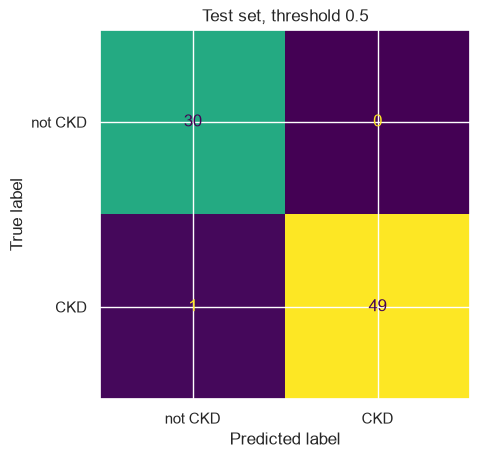

In [8]:
p_test = model.predict(A_test, verbose=0).ravel()
pred = (p_test >= 0.5).astype(int)
metrics = {
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall (sensitivity)": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "ROC AUC": roc_auc_score(y_test, p_test),
}
print(pd.Series(metrics).round(4).to_string())
print()
print(classification_report(y_test, pred, target_names=["not CKD", "CKD"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["not CKD", "CKD"], colorbar=False)
plt.title("Test set, threshold 0.5")
plt.show()

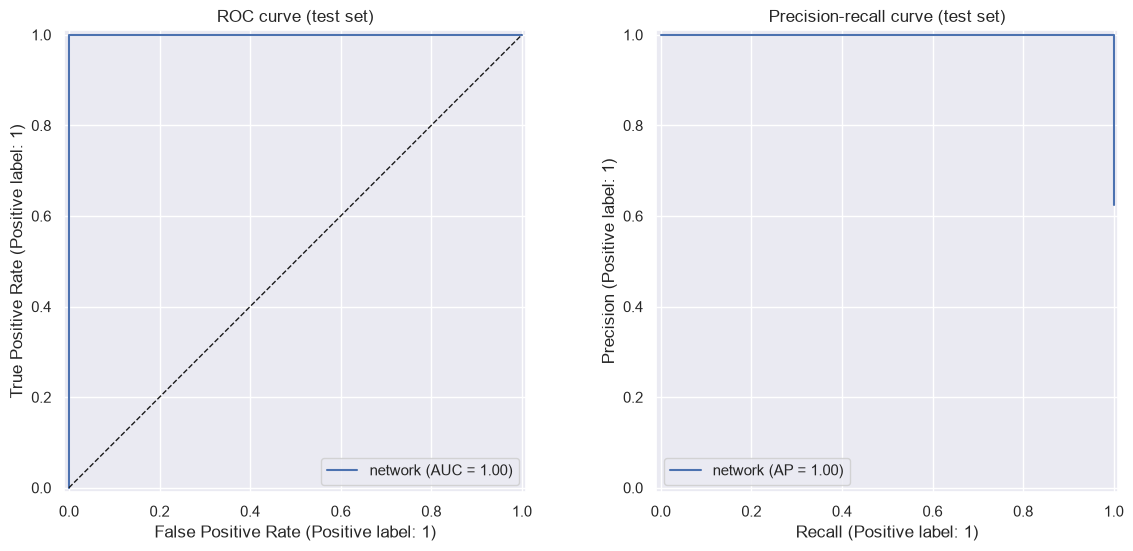

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax1, name="network")
ax1.plot([0, 1], [0, 1], "k--", lw=1)
ax1.set_title("ROC curve (test set)")
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=ax2, name="network")
ax2.set_title("Precision-recall curve (test set)")
plt.show()

## Choosing the decision threshold on the validation set

The threshold that maximises F1 is picked on the **validation** rows and then applied to the test rows, so the test
set plays no part in tuning.

threshold chosen on validation: 0.890 (validation F1 1.0000)
test accuracy at that threshold: 0.9750 | test F1: 0.9796


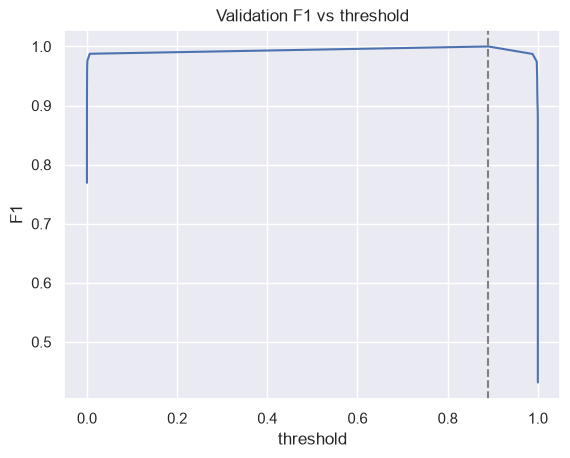

In [10]:
p_val = model.predict(A_val, verbose=0).ravel()
prec, rec, thr = precision_recall_curve(y_val, p_val)
f1_val = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
threshold = float(thr[np.argmax(f1_val)])
pred_thr = (p_test >= threshold).astype(int)
print(f"threshold chosen on validation: {threshold:.3f} (validation F1 {f1_val.max():.4f})")
print(f"test accuracy at that threshold: {accuracy_score(y_test, pred_thr):.4f} | test F1: {f1_score(y_test, pred_thr):.4f}")

plt.plot(thr, f1_val)
plt.axvline(threshold, color="grey", ls="--")
plt.title("Validation F1 vs threshold")
plt.xlabel("threshold")
plt.ylabel("F1")
plt.show()

## Repeated cross-validation

The 80-row test set is small: one patient is 1.25 points of accuracy. Repeating the **whole** pipeline (split off a
validation fold for early stopping, fit preprocessing, train, evaluate) over 5-fold stratified cross-validation,
3 times with different shuffles, gives 15 independent test folds.

In [11]:
def run_fold(X_fit_all, y_fit_all, X_eval, y_eval, seed):
    keras.utils.set_random_seed(seed)
    X_fit, X_v, y_fit, y_v = train_test_split(X_fit_all, y_fit_all, test_size=0.2, stratify=y_fit_all, random_state=seed)
    A_fit, yb_fit, tf = fit_preprocessing(X_fit, y_fit, seed)
    net = build_model(A_fit.shape[1])
    net.fit(A_fit, yb_fit, validation_data=(tf(X_v), y_v), epochs=500, batch_size=32, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)])
    p = net.predict(tf(X_eval), verbose=0).ravel()
    return {"accuracy": accuracy_score(y_eval, p >= 0.5), "F1": f1_score(y_eval, p >= 0.5),
            "recall": recall_score(y_eval, p >= 0.5), "precision": precision_score(y_eval, p >= 0.5),
            "ROC AUC": roc_auc_score(y_eval, p)}


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
fold_scores = pd.DataFrame([run_fold(X.iloc[a], y[a], X.iloc[b], y[b], seed=i)
                            for i, (a, b) in enumerate(cv.split(X, y))])
print(fold_scores.agg(["mean", "std", "min", "max"]).round(4).to_string())

      accuracy      F1  recall  precision  ROC AUC
mean    0.9925  0.9939  0.9880        1.0      1.0
std     0.0114  0.0093  0.0182        0.0      0.0
min     0.9625  0.9691  0.9400        1.0      1.0
max     1.0000  1.0000  1.0000        1.0      1.0
